In [3]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# 设置数据和图片保存目录
data_dir = r"D:\AI-Internship\Week03_Kaggle_Tabular\data\titanic"
fig_dir = r"D:\AI-Internship\Week03_Kaggle_Tabular\results\figures"

os.makedirs(fig_dir, exist_ok=True)

# 读取训练集和测试集
train = pd.read_csv(os.path.join(data_dir, "train.csv"))
test = pd.read_csv(os.path.join(data_dir, "test.csv"))

# 查看数据规模和前五行
print("训练集形状：", train.shape)
print("测试集形状：", test.shape)

display(train.head())

训练集形状： (891, 12)
测试集形状： (418, 11)


,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


In [4]:
# 检查数据类型和缺失值
print("训练集数据类型：")
print(train.dtypes)

print("\n训练集缺失值：")
train_null = train.isnull().sum()
print(train_null[train_null > 0])

print("\n测试集缺失值：")
test_null = test.isnull().sum()
print(test_null[test_null > 0])

# 检查重复数据
print("\n训练集重复行数：", train.duplicated().sum())
print("测试集重复行数：", test.duplicated().sum())

# 查看数值特征的统计信息
display(train.describe())

训练集数据类型：
PassengerId      int64
Survived         int64
Pclass           int64
Name               str
Sex                str
Age            float64
SibSp            int64
Parch            int64
Ticket             str
Fare           float64
Cabin              str
Embarked           str
dtype: object

训练集缺失值：
Age         177
Cabin       687
Embarked      2
dtype: int64

测试集缺失值：
Age       86
Fare       1
Cabin    327
dtype: int64

训练集重复行数： 0
测试集重复行数： 0


,PassengerId,Survived,Pclass,Age,SibSp,Parch,Fare
count,891.000000,891.000000,891.000000,714.000000,891.000000,891.000000,891.000000
mean,446.000000,0.383838,2.308642,29.699118,0.523008,0.381594,32.204208
std,257.353842,0.486592,0.836071,14.526497,1.102743,0.806057,49.693429
min,1.000000,0.000000,1.000000,0.420000,0.000000,0.000000,0.000000
25%,223.500000,0.000000,2.000000,20.125000,0.000000,0.000000,7.910400
50%,446.000000,0.000000,3.000000,28.000000,0.000000,0.000000,14.454200
75%,668.500000,1.000000,3.000000,38.000000,1.000000,0.000000,31.000000
max,891.000000,1.000000,3.000000,80.000000,8.000000,6.000000,512.329200


生还人数分布：
Survived
0    549
1    342
Name: count, dtype: int64

生还比例：
Survived
0    0.616162
1    0.383838
Name: proportion, dtype: float64


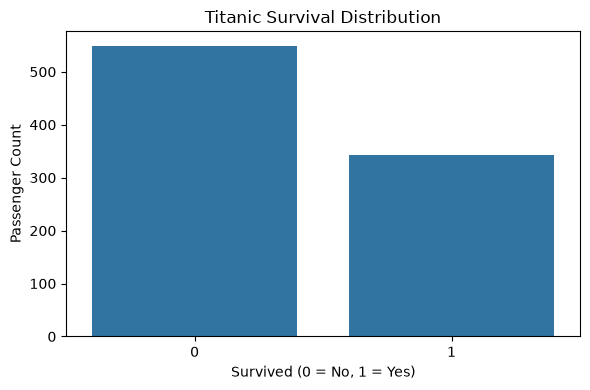

In [5]:
# 统计生还人数与比例
print("生还人数分布：")
print(train["Survived"].value_counts())

print("\n生还比例：")
print(train["Survived"].value_counts(normalize=True))

# 绘制生还人数分布
plt.figure(figsize=(6, 4))
sns.countplot(data=train, x="Survived")

plt.title("Titanic Survival Distribution")
plt.xlabel("Survived (0 = No, 1 = Yes)")
plt.ylabel("Passenger Count")
plt.tight_layout()

plt.savefig(
    os.path.join(fig_dir, "titanic_survival_distribution.png"),
    dpi=300
)
plt.show()

不同性别的生存情况：


,count,mean
Sex,,
female,314,0.742038
male,577,0.188908


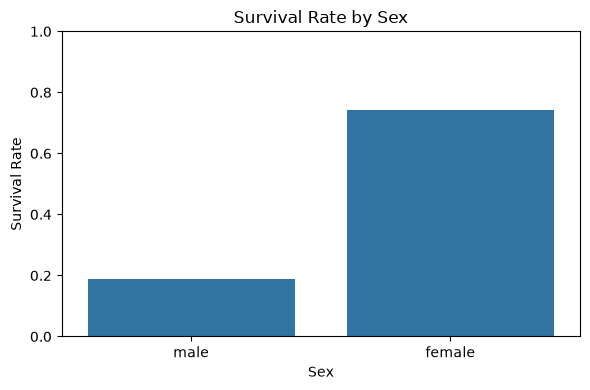

In [6]:
# 计算不同性别的生存率
sex_survival = train.groupby("Sex")["Survived"].agg(
    ["count", "mean"]
)

print("不同性别的生存情况：")
display(sex_survival)

# 绘制性别与生存率关系
plt.figure(figsize=(6, 4))

sns.barplot(
    data=train,
    x="Sex",
    y="Survived",
    errorbar=None
)

plt.title("Survival Rate by Sex")
plt.xlabel("Sex")
plt.ylabel("Survival Rate")
plt.ylim(0, 1)
plt.tight_layout()

plt.savefig(
    os.path.join(fig_dir, "titanic_survival_by_sex.png"),
    dpi=300
)

plt.show()

不同船票等级的生存情况：


,count,mean
Pclass,,
1,216,0.629630
2,184,0.472826
3,491,0.242363


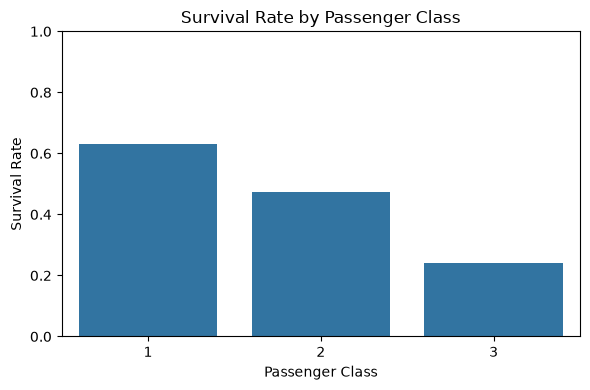

In [7]:
# 计算不同船票等级的生存率
pclass_survival = train.groupby("Pclass")["Survived"].agg(
    ["count", "mean"]
)

print("不同船票等级的生存情况：")
display(pclass_survival)

# 绘制船票等级与生存率关系
plt.figure(figsize=(6, 4))

sns.barplot(
    data=train,
    x="Pclass",
    y="Survived",
    errorbar=None
)

plt.title("Survival Rate by Passenger Class")
plt.xlabel("Passenger Class")
plt.ylabel("Survival Rate")
plt.ylim(0, 1)
plt.tight_layout()

plt.savefig(
    os.path.join(fig_dir, "titanic_survival_by_pclass.png"),
    dpi=300
)

plt.show()

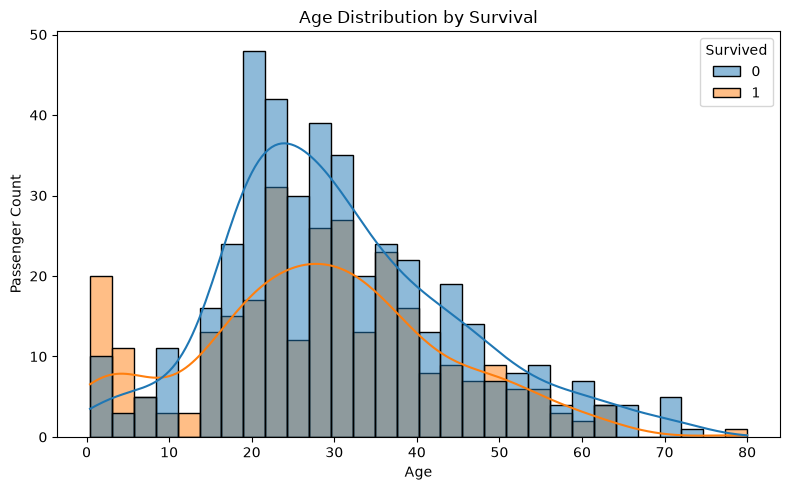

不同年龄组的生存率：


,count,mean
AgeGroup,,
Child,69,0.579710
Teen,70,0.428571
Young Adult,358,0.382682
Adult,195,0.400000
Senior,22,0.227273


In [8]:
# 查看不同生存状态的年龄分布
plt.figure(figsize=(8, 5))

sns.histplot(
    data=train,
    x="Age",
    hue="Survived",
    bins=30,
    kde=True,
    alpha=0.5
)

plt.title("Age Distribution by Survival")
plt.xlabel("Age")
plt.ylabel("Passenger Count")
plt.tight_layout()

plt.savefig(
    os.path.join(fig_dir, "titanic_age_distribution.png"),
    dpi=300
)

plt.show()

# 创建年龄分组用于探索性分析
age_bins = [0, 12, 18, 35, 60, np.inf]
age_labels = ["Child", "Teen", "Young Adult", "Adult", "Senior"]

age_analysis = train.copy()

age_analysis["AgeGroup"] = pd.cut(
    age_analysis["Age"],
    bins=age_bins,
    labels=age_labels,
    include_lowest=True
)

# 统计不同年龄组的生存率
print("不同年龄组的生存率：")
display(
    age_analysis.groupby("AgeGroup", observed=True)["Survived"]
    .agg(["count", "mean"])
)

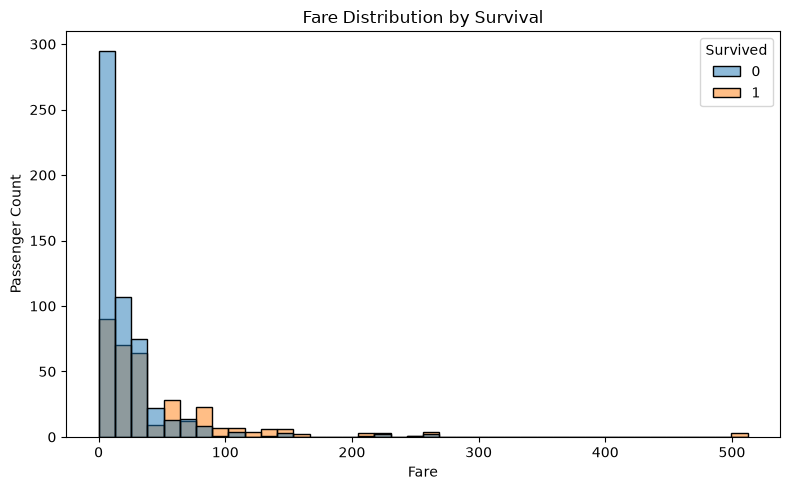

不同票价区间的生存率：


,count,mean
FareGroup,,
"(-0.001, 7.91]",223,0.197309
"(7.91, 14.454]",224,0.303571
"(14.454, 31.0]",222,0.454955
"(31.0, 512.329]",222,0.581081


In [9]:
# 绘制不同生存状态的票价分布
plt.figure(figsize=(8, 5))

sns.histplot(
    data=train,
    x="Fare",
    hue="Survived",
    bins=40,
    alpha=0.5
)

plt.title("Fare Distribution by Survival")
plt.xlabel("Fare")
plt.ylabel("Passenger Count")
plt.tight_layout()

plt.savefig(
    os.path.join(fig_dir, "titanic_fare_distribution.png"),
    dpi=300
)

plt.show()

# 按票价分位数划分区间
fare_analysis = train.copy()

fare_analysis["FareGroup"] = pd.qcut(
    fare_analysis["Fare"],
    q=4,
    duplicates="drop"
)

print("不同票价区间的生存率：")
display(
    fare_analysis.groupby("FareGroup", observed=True)["Survived"]
    .agg(["count", "mean"])
)

In [10]:

# 复制原始数据，避免修改 EDA 使用的数据
train_fe = train.copy()
test_fe = test.copy()

# 提取乘客姓名中的称谓
for df in [train_fe, test_fe]:
    df["Title"] = df["Name"].str.extract(r",\s*([^.]*)\.", expand=False).str.strip()

    # 计算家庭总人数
    df["FamilySize"] = df["SibSp"] + df["Parch"] + 1

    # 判断是否独自旅行
    df["IsAlone"] = (df["FamilySize"] == 1).astype(int)

# 查看称谓分布
print("训练集 Title 分布：")
print(train_fe["Title"].value_counts())

print("\n测试集 Title 分布：")
print(test_fe["Title"].value_counts())

# 查看新特征
display(
    train_fe[
        ["Name", "Title", "SibSp", "Parch", "FamilySize", "IsAlone"]
    ].head(10)
)


训练集 Title 分布：
Title
Mr              517
Miss            182
Mrs             125
Master           40
Dr                7
Rev               6
Major             2
Mlle              2
Col               2
Don               1
Mme               1
Ms                1
Lady              1
Sir               1
Capt              1
the Countess      1
Jonkheer          1
Name: count, dtype: int64

测试集 Title 分布：
Title
Mr        240
Miss       78
Mrs        72
Master     21
Col         2
Rev         2
Ms          1
Dr          1
Dona        1
Name: count, dtype: int64


,Name,Title,SibSp,Parch,FamilySize,IsAlone
0,"Braund, Mr. Owen Harris",Mr,1,0,2,0
1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",Mrs,1,0,2,0
2,"Heikkinen, Miss. Laina",Miss,0,0,1,1
3,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",Mrs,1,0,2,0
4,"Allen, Mr. William Henry",Mr,0,0,1,1
5,"Moran, Mr. James",Mr,0,0,1,1
6,"McCarthy, Mr. Timothy J",Mr,0,0,1,1
7,"Palsson, Master. Gosta Leonard",Master,3,1,5,0
8,"Johnson, Mrs. Oscar W (Elisabeth Vilhelmina Berg)",Mrs,0,2,3,0
9,"Nasser, Mrs. Nicholas (Adele Achem)",Mrs,1,0,2,0


In [11]:

# 检查特征是否成功创建
new_features = ["Title", "FamilySize", "IsAlone"]

print("训练集新增特征缺失值：")
print(train_fe[new_features].isnull().sum())

print("\n测试集新增特征缺失值：")
print(test_fe[new_features].isnull().sum())

print("\n训练集形状：", train_fe.shape)
print("测试集形状：", test_fe.shape)


训练集新增特征缺失值：
Title         0
FamilySize    0
IsAlone       0
dtype: int64

测试集新增特征缺失值：
Title         0
FamilySize    0
IsAlone       0
dtype: int64

训练集形状： (891, 15)
测试集形状： (418, 14)


In [12]:

from sklearn.model_selection import train_test_split

# 分离特征和预测目标
X = train_fe.drop(columns=["Survived"])
y = train_fe["Survived"]

# 分层划分训练集与验证集
X_train, X_val, y_train, y_val = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

# 检查数据规模
print("训练特征形状：", X_train.shape)
print("验证特征形状：", X_val.shape)

print("\n训练集生存率：", round(y_train.mean(), 4))
print("验证集生存率：", round(y_val.mean(), 4))


训练特征形状： (712, 14)
验证特征形状： (179, 14)

训练集生存率： 0.3834
验证集生存率： 0.3855


In [13]:

from sklearn.impute import SimpleImputer

# 复制数据，避免覆盖原始划分
X_train_clean = X_train.copy()
X_val_clean = X_val.copy()
X_test_clean = test_fe.copy()

# 数值特征使用训练集的中位数填补
num_cols = ["Age", "Fare"]
num_imputer = SimpleImputer(strategy="median")

X_train_clean[num_cols] = num_imputer.fit_transform(
    X_train[num_cols]
)

X_val_clean[num_cols] = num_imputer.transform(
    X_val[num_cols]
)

X_test_clean[num_cols] = num_imputer.transform(
    test_fe[num_cols]
)

# 类别特征使用训练集的众数填补
cat_cols = ["Embarked"]
cat_imputer = SimpleImputer(strategy="most_frequent")

X_train_clean[cat_cols] = cat_imputer.fit_transform(
    X_train[cat_cols]
)

X_val_clean[cat_cols] = cat_imputer.transform(
    X_val[cat_cols]
)

X_test_clean[cat_cols] = cat_imputer.transform(
    test_fe[cat_cols]
)

# 检查三个数据集的关键缺失值
for name, df in [
    ("训练集", X_train_clean),
    ("验证集", X_val_clean),
    ("Kaggle测试集", X_test_clean)
]:
    print(f"\n{name}：")
    print(df[["Age", "Fare", "Embarked"]].isnull().sum())



训练集：
Age         0
Fare        0
Embarked    0
dtype: int64

验证集：
Age         0
Fare        0
Embarked    0
dtype: int64

Kaggle测试集：
Age         0
Fare        0
Embarked    0
dtype: int64


In [14]:

# 设置年龄分箱边界
age_bins = [0, 12, 18, 35, 60, np.inf]
age_labels = ["Child", "Teen", "YoungAdult", "Adult", "Senior"]

# 使用训练集计算票价分位数边界
fare_bins = np.quantile(
    X_train_clean["Fare"],
    [0, 0.25, 0.5, 0.75, 1]
)

# 确保边界可以覆盖测试集中的所有票价
fare_bins[0] = -np.inf
fare_bins[-1] = np.inf

# 去除可能重复的分箱边界
fare_bins = np.unique(fare_bins)

# 为三个数据集创建分箱特征
for df in [X_train_clean, X_val_clean, X_test_clean]:

    df["AgeBin"] = pd.cut(
        df["Age"],
        bins=age_bins,
        labels=age_labels,
        include_lowest=True
    )

    df["FareBin"] = pd.cut(
        df["Fare"],
        bins=fare_bins,
        labels=False,
        include_lowest=True
    )

# 查看分箱边界
print("票价分箱边界：", fare_bins)

# 查看新增特征
display(
    X_train_clean[
        ["Age", "AgeBin", "Fare", "FareBin"]
    ].head(10)
)


票价分箱边界： [   -inf  7.8958 14.4542 31.         inf]


,Age,AgeBin,Fare,FareBin
692,28.5,YoungAdult,56.4958,3
481,28.5,YoungAdult,0.0000,0
527,28.5,YoungAdult,221.7792,3
855,18.0,Teen,9.3500,1
801,31.0,YoungAdult,26.2500,2
652,21.0,YoungAdult,8.4333,1
509,26.0,YoungAdult,56.4958,3
557,28.5,YoungAdult,227.5250,3
828,28.5,YoungAdult,7.7500,0
18,31.0,YoungAdult,18.0000,2


In [15]:

# 检查新增特征的缺失值和类别数量
for name, df in [
    ("训练集", X_train_clean),
    ("验证集", X_val_clean),
    ("Kaggle测试集", X_test_clean)
]:
    print(f"\n{name}：")
    print("数据形状：", df.shape)
    print("AgeBin 缺失值：", df["AgeBin"].isnull().sum())
    print("FareBin 缺失值：", df["FareBin"].isnull().sum())
    print("AgeBin 类别数：", df["AgeBin"].nunique())
    print("FareBin 类别数：", df["FareBin"].nunique())

# 查看训练集年龄分箱分布
print("\n训练集年龄分箱分布：")
print(X_train_clean["AgeBin"].value_counts().sort_index())

# 查看训练集票价分箱分布
print("\n训练集票价分箱分布：")
print(X_train_clean["FareBin"].value_counts().sort_index())



训练集：
数据形状： (712, 16)
AgeBin 缺失值： 0
FareBin 缺失值： 0
AgeBin 类别数： 5
FareBin 类别数： 4

验证集：
数据形状： (179, 16)
AgeBin 缺失值： 0
FareBin 缺失值： 0
AgeBin 类别数： 5
FareBin 类别数： 4

Kaggle测试集：
数据形状： (418, 16)
AgeBin 缺失值： 0
FareBin 缺失值： 0
AgeBin 类别数： 5
FareBin 类别数： 4

训练集年龄分箱分布：
AgeBin
Child          55
Teen           53
YoungAdult    421
Adult         167
Senior         16
Name: count, dtype: int64

训练集票价分箱分布：
FareBin
0    180
1    181
2    175
3    176
Name: count, dtype: int64


In [16]:

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder

# 选择数值特征和类别特征
numeric_features = [
    "Age", "Fare", "SibSp", "Parch",
    "FamilySize", "IsAlone"
]

categorical_features = [
    "Pclass", "Sex", "Embarked",
    "Title", "AgeBin", "FareBin"
]

selected_features = numeric_features + categorical_features

# 选择三个数据集的特征
X_train_selected = X_train_clean[selected_features].copy()
X_val_selected = X_val_clean[selected_features].copy()
X_test_selected = X_test_clean[selected_features].copy()

# 创建类别编码器
preprocessor = ColumnTransformer(
    transformers=[
        ("num", "passthrough", numeric_features),
        ("cat", OneHotEncoder(
            handle_unknown="ignore",
            sparse_output=False
        ), categorical_features)
    ]
)

# 仅使用训练集学习编码规则
X_train_encoded = preprocessor.fit_transform(X_train_selected)

# 验证集和测试集使用相同规则
X_val_encoded = preprocessor.transform(X_val_selected)
X_test_encoded = preprocessor.transform(X_test_selected)

# 获取编码后的特征名称
feature_names = preprocessor.get_feature_names_out()

print("训练集编码后形状：", X_train_encoded.shape)
print("验证集编码后形状：", X_val_encoded.shape)
print("测试集编码后形状：", X_test_encoded.shape)
print("编码后特征数量：", len(feature_names))


训练集编码后形状： (712, 37)
验证集编码后形状： (179, 37)
测试集编码后形状： (418, 37)
编码后特征数量： 37


In [17]:

# 转换为 DataFrame，方便检查
encoded_train_df = pd.DataFrame(
    X_train_encoded,
    columns=feature_names,
    index=X_train_selected.index
)

# 查看编码结果
display(encoded_train_df.head())

# 检查三个数据集是否含有缺失值
for name, data in [
    ("训练集", X_train_encoded),
    ("验证集", X_val_encoded),
    ("Kaggle测试集", X_test_encoded)
]:
    print(f"{name}形状：{data.shape}")
    print("缺失值数量：", np.isnan(data).sum())
    print("无穷值数量：", np.isinf(data).sum())
    print()

# 检查编码后的特征名称
print("全部编码特征：")
print(feature_names.tolist())


,num__Age,num__Fare,num__SibSp,num__Parch,num__FamilySize,num__IsAlone,cat__Pclass_1,cat__Pclass_2,cat__Pclass_3,cat__Sex_female,...,cat__Title_Sir,cat__AgeBin_Adult,cat__AgeBin_Child,cat__AgeBin_Senior,cat__AgeBin_Teen,cat__AgeBin_YoungAdult,cat__FareBin_0,cat__FareBin_1,cat__FareBin_2,cat__FareBin_3
692,28.5,56.4958,0.0,0.0,1.0,1.0,0.0,0.0,1.0,0.0,...,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0
481,28.5,0.0000,0.0,0.0,1.0,1.0,0.0,1.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,1.0,1.0,0.0,0.0,0.0
527,28.5,221.7792,0.0,0.0,1.0,1.0,1.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0
855,18.0,9.3500,0.0,1.0,2.0,0.0,0.0,0.0,1.0,1.0,...,0.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0
801,31.0,26.2500,1.0,1.0,3.0,0.0,0.0,1.0,0.0,1.0,...,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0


训练集形状：(712, 37)
缺失值数量： 0
无穷值数量： 0

验证集形状：(179, 37)
缺失值数量： 0
无穷值数量： 0

Kaggle测试集形状：(418, 37)
缺失值数量： 0
无穷值数量： 0

全部编码特征：
['num__Age', 'num__Fare', 'num__SibSp', 'num__Parch', 'num__FamilySize', 'num__IsAlone', 'cat__Pclass_1', 'cat__Pclass_2', 'cat__Pclass_3', 'cat__Sex_female', 'cat__Sex_male', 'cat__Embarked_C', 'cat__Embarked_Q', 'cat__Embarked_S', 'cat__Title_Col', 'cat__Title_Don', 'cat__Title_Dr', 'cat__Title_Jonkheer', 'cat__Title_Lady', 'cat__Title_Major', 'cat__Title_Master', 'cat__Title_Miss', 'cat__Title_Mlle', 'cat__Title_Mr', 'cat__Title_Mrs', 'cat__Title_Ms', 'cat__Title_Rev', 'cat__Title_Sir', 'cat__AgeBin_Adult', 'cat__AgeBin_Child', 'cat__AgeBin_Senior', 'cat__AgeBin_Teen', 'cat__AgeBin_YoungAdult', 'cat__FareBin_0', 'cat__FareBin_1', 'cat__FareBin_2', 'cat__FareBin_3']


In [18]:

from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.model_selection import StratifiedKFold, cross_validate
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score

# 使用训练集学习票价分箱边界
class FareBinner(BaseEstimator, TransformerMixin):
    def fit(self, X, y=None):
        fare = pd.to_numeric(X["Fare"], errors="coerce")
        median = fare.median()
        values = fare.fillna(median)
        edges = np.quantile(values, [0, 0.25, 0.5, 0.75, 1])
        edges[0], edges[-1] = -np.inf, np.inf
        self.edges_ = np.unique(edges)
        self.median_ = median
        return self

    def transform(self, X):
        X = X.copy()
        fare = pd.to_numeric(X["Fare"], errors="coerce")
        X["FareBin"] = pd.cut(
            fare.fillna(self.median_),
            bins=self.edges_,
            labels=False,
            include_lowest=True
        ).astype(str)
        return X

# 构建年龄分箱并筛选特征
class FeatureBuilder(BaseEstimator, TransformerMixin):
    def fit(self, X, y=None):
        return self

    def transform(self, X):
        X = X.copy()
        X["AgeBin"] = pd.cut(
            X["Age"],
            bins=[0, 12, 18, 35, 60, np.inf],
            labels=["Child", "Teen", "YoungAdult", "Adult", "Senior"],
            include_lowest=True
        ).astype(object)
        X["AgeBin"] = X["AgeBin"].fillna("Unknown")
        X["Pclass"] = X["Pclass"].astype(str)
        return X[selected_features]

# 数值与类别预处理
numeric_pipe = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_pipe = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

model_preprocessor = ColumnTransformer([
    ("num", numeric_pipe, numeric_features),
    ("cat", categorical_pipe, categorical_features)
])

# 定义四个分类模型
models = {
    "Logistic Regression": LogisticRegression(max_iter=2000, random_state=42),
    "Decision Tree": DecisionTreeClassifier(max_depth=5, random_state=42),
    "Random Forest": RandomForestClassifier(
        n_estimators=200, random_state=42, n_jobs=-1
    ),
    "Gradient Boosting": GradientBoostingClassifier(random_state=42)
}

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

cv_results = []
val_results = []
fitted_models = {}

for name, model in models.items():
    pipeline = Pipeline([
        ("fare_binning", FareBinner()),
        ("features", FeatureBuilder()),
        ("preprocess", model_preprocessor),
        ("model", model)
    ])

    # 在训练集进行五折交叉验证
    scores = cross_validate(
        pipeline,
        X_train,
        y_train,
        cv=cv,
        scoring={
            "Accuracy": "accuracy",
            "Precision": "precision",
            "Recall": "recall",
            "F1": "f1",
            "ROC_AUC": "roc_auc"
        },
        n_jobs=1
    )

    cv_row = {"Model": name}
    for metric in ["Accuracy", "Precision", "Recall", "F1", "ROC_AUC"]:
        cv_row[metric] = scores[f"test_{metric}"].mean()
        cv_row[f"{metric}_Std"] = scores[f"test_{metric}"].std()

    cv_results.append(cv_row)

    # 在完整训练集拟合并评估独立验证集
    pipeline.fit(X_train, y_train)
    pred = pipeline.predict(X_val)
    prob = pipeline.predict_proba(X_val)[:, 1]

    val_results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_val, pred),
        "Precision": precision_score(y_val, pred, zero_division=0),
        "Recall": recall_score(y_val, pred, zero_division=0),
        "F1": f1_score(y_val, pred, zero_division=0),
        "ROC_AUC": roc_auc_score(y_val, prob)
    })

    fitted_models[name] = pipeline
    print(f"{name} 完成")

# 整理结果
cv_df = pd.DataFrame(cv_results).sort_values("ROC_AUC", ascending=False)
val_df = pd.DataFrame(val_results).sort_values("ROC_AUC", ascending=False)

print("\n五折交叉验证结果：")
display(cv_df.round(4))

print("\n独立验证集结果：")
display(val_df.round(4))


Logistic Regression 完成
Decision Tree 完成
Random Forest 完成
Gradient Boosting 完成

五折交叉验证结果：


,Model,Accuracy,Accuracy_Std,Precision,Precision_Std,Recall,Recall_Std,F1,F1_Std,ROC_AUC,ROC_AUC_Std
3,Gradient Boosting,0.8174,0.0329,0.8011,0.0685,0.7032,0.0430,0.7474,0.0422,0.8933,0.0168
0,Logistic Regression,0.8174,0.0288,0.7814,0.0598,0.7363,0.0269,0.7565,0.0296,0.8642,0.0231
2,Random Forest,0.8132,0.0111,0.7679,0.0171,0.7363,0.0359,0.7511,0.0178,0.8593,0.0176
1,Decision Tree,0.7963,0.0185,0.7642,0.0459,0.6850,0.0420,0.7205,0.0227,0.8306,0.0173



独立验证集结果：


,Model,Accuracy,Precision,Recall,F1,ROC_AUC
0,Logistic Regression,0.8380,0.8125,0.7536,0.7820,0.8748
3,Gradient Boosting,0.8045,0.7931,0.6667,0.7244,0.8495
1,Decision Tree,0.8156,0.7571,0.7681,0.7626,0.8353
2,Random Forest,0.8101,0.7612,0.7391,0.7500,0.8213


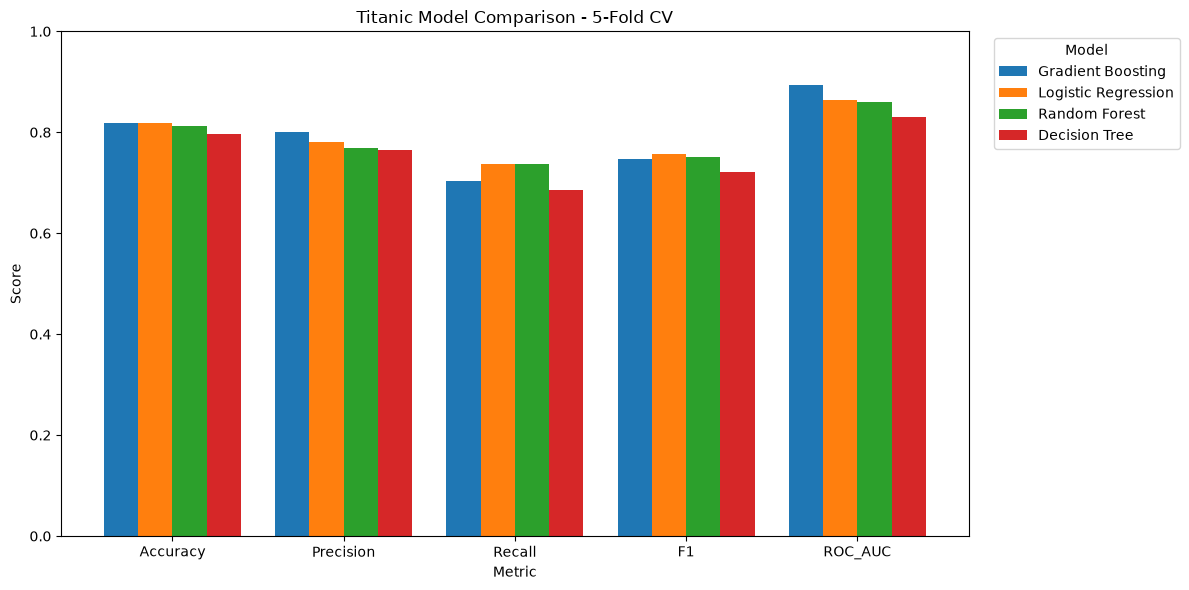

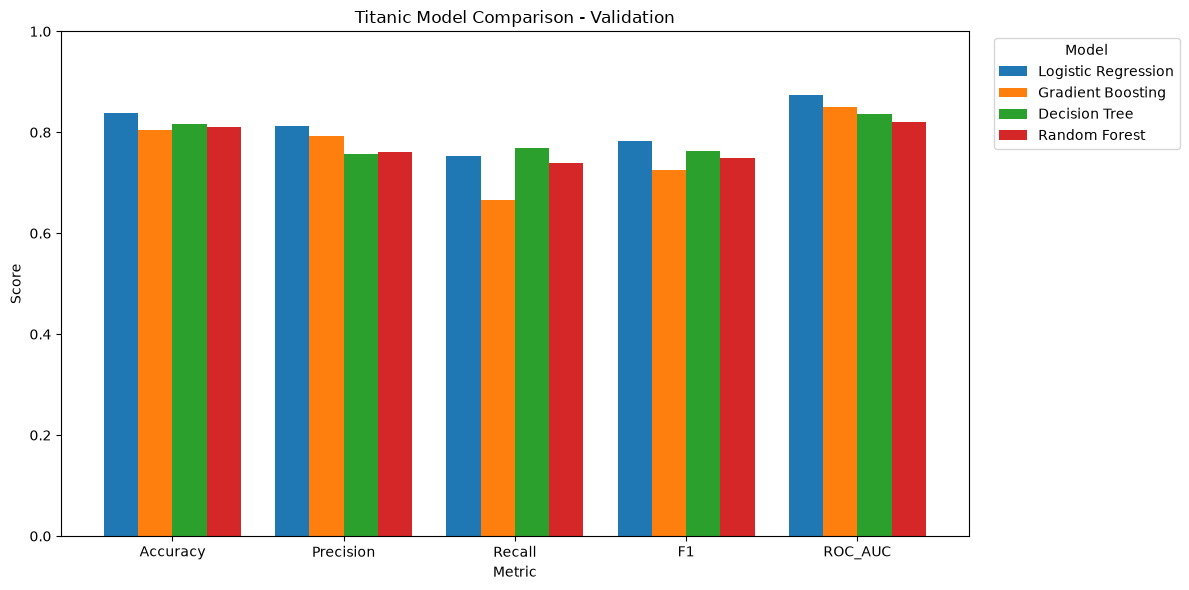

模型比较 CSV 和 PNG 保存成功


In [19]:

# 保存模型评估结果
results_dir = os.path.dirname(fig_dir)

cv_df.to_csv(
    os.path.join(results_dir, "titanic_cv_comparison.csv"),
    index=False
)

val_df.to_csv(
    os.path.join(results_dir, "titanic_validation_comparison.csv"),
    index=False
)

# 绘制五折交叉验证模型比较图
metrics = ["Accuracy", "Precision", "Recall", "F1", "ROC_AUC"]

cv_plot = cv_df.set_index("Model")[metrics].T

ax = cv_plot.plot(kind="bar", figsize=(12, 6), width=0.8)
ax.set_title("Titanic Model Comparison - 5-Fold CV")
ax.set_ylabel("Score")
ax.set_xlabel("Metric")
ax.set_ylim(0, 1)
ax.tick_params(axis="x", rotation=0)
ax.legend(title="Model", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()

plt.savefig(
    os.path.join(fig_dir, "titanic_cv_model_comparison.png"),
    dpi=300,
    bbox_inches="tight"
)
plt.show()

# 绘制独立验证集模型比较图
ax = val_df.set_index("Model")[metrics].T.plot(
    kind="bar",
    figsize=(12, 6),
    width=0.8
)
ax.set_title("Titanic Model Comparison - Validation")
ax.set_ylabel("Score")
ax.set_xlabel("Metric")
ax.set_ylim(0, 1)
ax.tick_params(axis="x", rotation=0)
ax.legend(title="Model", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()

plt.savefig(
    os.path.join(fig_dir, "titanic_validation_model_comparison.png"),
    dpi=300,
    bbox_inches="tight"
)
plt.show()

print("模型比较 CSV 和 PNG 保存成功")


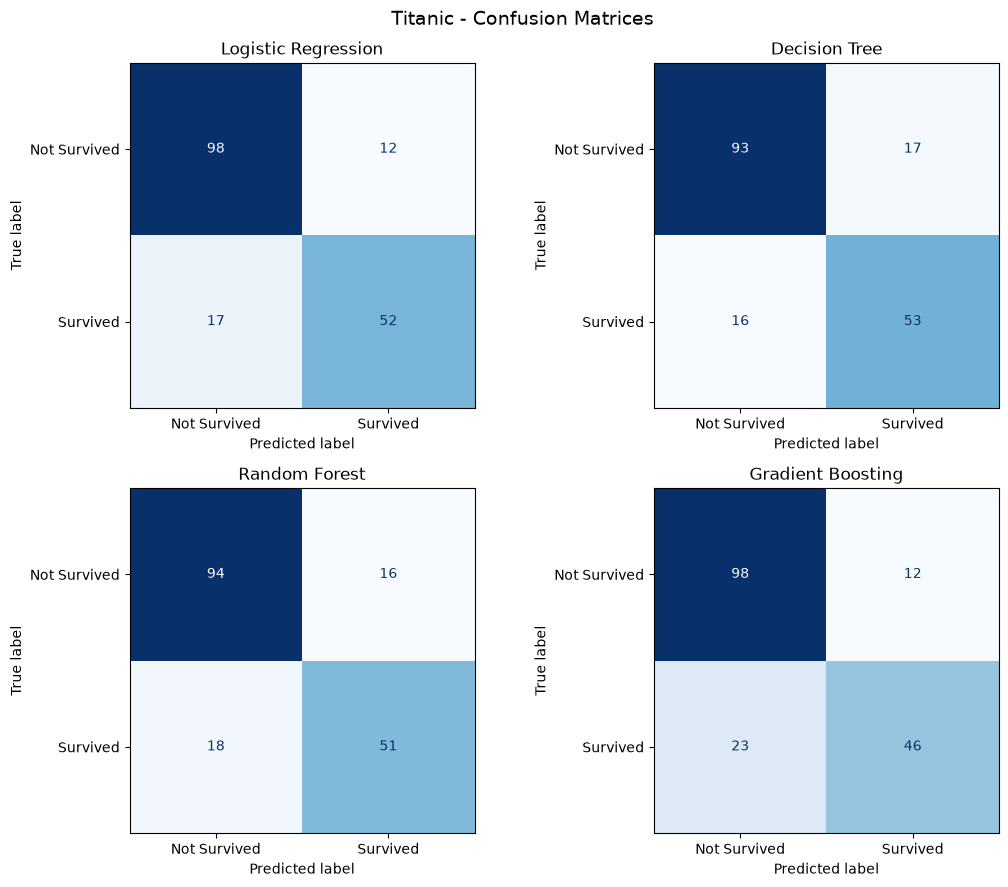

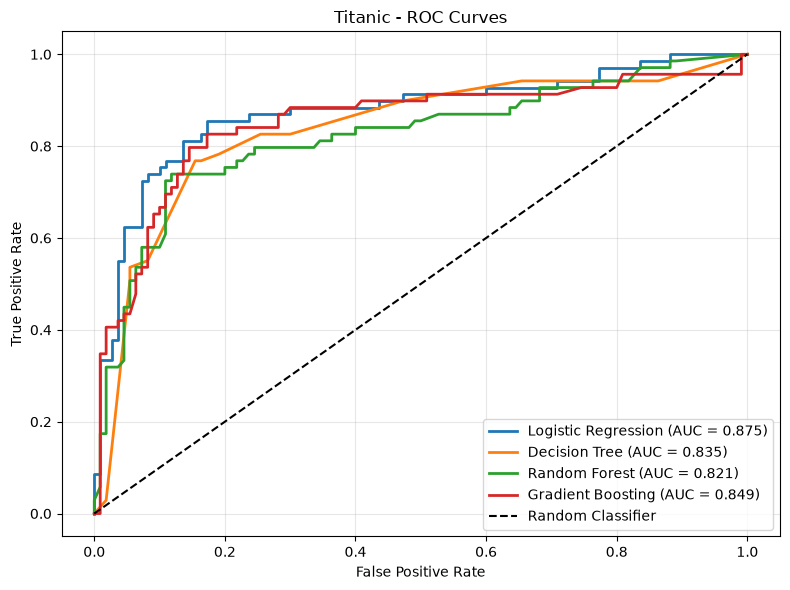

混淆矩阵与 ROC 曲线保存成功


In [20]:

from sklearn.metrics import ConfusionMatrixDisplay, roc_curve, auc
import matplotlib.pyplot as plt

# 绘制四个模型的混淆矩阵
fig, axes = plt.subplots(2, 2, figsize=(11, 9))

for ax, (name, model) in zip(axes.flat, fitted_models.items()):
    pred = model.predict(X_val)

    ConfusionMatrixDisplay.from_predictions(
        y_val,
        pred,
        display_labels=["Not Survived", "Survived"],
        cmap="Blues",
        colorbar=False,
        ax=ax
    )
    ax.set_title(name)

plt.suptitle("Titanic - Confusion Matrices", fontsize=14)
plt.tight_layout()

plt.savefig(
    os.path.join(fig_dir, "titanic_confusion_matrices.png"),
    dpi=300,
    bbox_inches="tight"
)
plt.show()

# 绘制四个模型的 ROC 曲线
plt.figure(figsize=(8, 6))

for name, model in fitted_models.items():
    prob = model.predict_proba(X_val)[:, 1]
    fpr, tpr, _ = roc_curve(y_val, prob)
    roc_auc = auc(fpr, tpr)

    plt.plot(
        fpr,
        tpr,
        linewidth=2,
        label=f"{name} (AUC = {roc_auc:.3f})"
    )

plt.plot([0, 1], [0, 1], "k--", label="Random Classifier")

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("Titanic - ROC Curves")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()

plt.savefig(
    os.path.join(fig_dir, "titanic_roc_curves.png"),
    dpi=300
)
plt.show()

print("混淆矩阵与 ROC 曲线保存成功")


In [21]:

from sklearn.base import clone

# 根据交叉验证准确率选择两个模型
top_models = (
    cv_df.sort_values("Accuracy", ascending=False)
    .head(2)["Model"]
    .tolist()
)

print("选中的模型：", top_models)

# 使用全部有标签的数据重新训练
X_full = train_fe.drop(columns=["Survived"])
y_full = train_fe["Survived"]
X_kaggle = test_fe.copy()

submission_files = []

for i, name in enumerate(top_models, start=1):
    # 克隆完整 Pipeline，重新训练模型
    final_model = clone(fitted_models[name])
    final_model.fit(X_full, y_full)

    # 预测 Kaggle 测试集
    predictions = final_model.predict(X_kaggle).astype(int)

    # 创建 Kaggle 提交文件
    submission = pd.DataFrame({
        "PassengerId": X_kaggle["PassengerId"],
        "Survived": predictions
    })

    # 验证提交格式
    assert submission.shape == (418, 2)
    assert submission["PassengerId"].is_unique
    assert submission["Survived"].isin([0, 1]).all()
    assert submission.isnull().sum().sum() == 0

    # 保存提交结果
    filename = f"titanic_submission_{i}.csv"
    filepath = os.path.join(results_dir, filename)

    submission.to_csv(filepath, index=False)
    submission_files.append((name, filename))

    print(f"\n提交 {i}：{name}")
    print("保存路径：", filepath)
    print("预测生还人数：", int(predictions.sum()))
    display(submission.head())

print("\n全部提交文件已生成：")
for name, filename in submission_files:
    print(f"{filename} -> {name}")


选中的模型： ['Gradient Boosting', 'Logistic Regression']

提交 1：Gradient Boosting
保存路径： D:\AI-Internship\Week03_Kaggle_Tabular\results\titanic_submission_1.csv
预测生还人数： 153


,PassengerId,Survived
0,892,0
1,893,0
2,894,0
3,895,0
4,896,1



提交 2：Logistic Regression
保存路径： D:\AI-Internship\Week03_Kaggle_Tabular\results\titanic_submission_2.csv
预测生还人数： 168


,PassengerId,Survived
0,892,0
1,893,1
2,894,0
3,895,0
4,896,1



全部提交文件已生成：
titanic_submission_1.csv -> Gradient Boosting
titanic_submission_2.csv -> Logistic Regression



## Kaggle Submission Results

Two submissions were successfully completed.

| Submission | Kaggle Accuracy |
|---|---|
| Submission 1 | 0.76794 |
| Submission 2 | 0.77990 |

Best Kaggle Accuracy: 0.77990

The second submission improved the accuracy by 1.196 percentage points.

Four classification models were compared using five-fold stratified cross-validation and an independent validation set.

The submission results demonstrate the effectiveness of model comparison and feature engineering.
